# EV Charging Station Recommendation — Final Milestone

This final notebook combines the executable fuzzy-controller foundation from Milestone 2 with the corrected testing, analysis, visualization, recommendation calculator, and comprehensive evaluation work from Milestone 3.

The fuzzy rules and membership functions are the project model. Uncovered combinations are not artificially assigned a score, because doing so would hide gaps in the rule base.

## 0. Setup

If this notebook is opened in a fresh environment, install the dependencies once with:

```
pip install numpy pandas matplotlib seaborn scikit-fuzzy ipywidgets
```

The code below does not reinstall packages on every run.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import skfuzzy as fuzz
import skfuzzy.control as ctrl

from IPython.display import display, clear_output

plt.style.use("seaborn-v0_8-darkgrid")
sns.set_palette("husl")

# Input and output universes
distance = ctrl.Antecedent(np.arange(0, 16, 1), "distance")
availability = ctrl.Antecedent(np.arange(0, 101, 1), "availability")
cost = ctrl.Antecedent(np.arange(0, 21, 1), "cost")
recommendation = ctrl.Consequent(np.arange(0, 101, 1), "recommendation")

# Membership functions
distance["close"] = fuzz.trimf(distance.universe, [0, 0, 5])
distance["medium"] = fuzz.trimf(distance.universe, [3, 7.5, 12])
distance["far"] = fuzz.trimf(distance.universe, [10, 15, 15])

availability["low"] = fuzz.trimf(availability.universe, [0, 0, 40])
availability["medium"] = fuzz.trimf(availability.universe, [20, 50, 80])
availability["high"] = fuzz.trimf(availability.universe, [60, 100, 100])

cost["cheap"] = fuzz.trimf(cost.universe, [0, 0, 8])
cost["moderate"] = fuzz.trimf(cost.universe, [4, 10, 16])
cost["expensive"] = fuzz.trimf(cost.universe, [12, 20, 20])

recommendation["poor"] = fuzz.trimf(recommendation.universe, [0, 0, 35])
recommendation["fair"] = fuzz.trimf(recommendation.universe, [20, 50, 80])
recommendation["excellent"] = fuzz.trimf(recommendation.universe, [65, 100, 100])

# Rule base
rule1 = ctrl.Rule(distance["close"] & availability["high"] & cost["cheap"], recommendation["excellent"])
rule2 = ctrl.Rule(distance["close"] & availability["high"] & cost["moderate"], recommendation["excellent"])
rule3 = ctrl.Rule(distance["close"] & availability["medium"] & cost["cheap"], recommendation["excellent"])
rule4 = ctrl.Rule(distance["medium"] & availability["high"] & cost["cheap"], recommendation["excellent"])
rule5 = ctrl.Rule(distance["medium"] & availability["medium"] & cost["cheap"], recommendation["fair"])
rule6 = ctrl.Rule(distance["medium"] & availability["high"] & cost["moderate"], recommendation["fair"])
rule7 = ctrl.Rule(distance["far"] | availability["low"] | cost["expensive"], recommendation["poor"])
rule8 = ctrl.Rule(distance["close"] & availability["medium"] & cost["expensive"], recommendation["fair"])
rule9 = ctrl.Rule(distance["medium"] & availability["medium"] & cost["moderate"], recommendation["fair"])
rule10 = ctrl.Rule(distance["far"] & availability["low"] & cost["expensive"], recommendation["poor"])

charging_system = ctrl.ControlSystem([
    rule1, rule2, rule3, rule4, rule5,
    rule6, rule7, rule8, rule9, rule10
])

VALID_DEFUZZIFICATION_METHODS = ("centroid", "bisector", "mom", "som", "lom")

def _validate_inputs(distance_val, availability_val, cost_val):
    values = {
        "distance": distance_val,
        "availability": availability_val,
        "cost": cost_val,
    }
    bounds = {
        "distance": (0, 15),
        "availability": (0, 100),
        "cost": (0, 20),
    }
    for name, value in values.items():
        if not np.isfinite(value):
            raise ValueError(f"{name} must be a finite number.")
        lower, upper = bounds[name]
        if not lower <= value <= upper:
            raise ValueError(f"{name} must be between {lower} and {upper}.")

def get_recommendation_score(
    distance_val,
    availability_val,
    cost_val,
    defuzzification_method="centroid",
):
    """Return a recommendation score, or NaN when no rule is activated."""
    _validate_inputs(distance_val, availability_val, cost_val)
    if defuzzification_method not in VALID_DEFUZZIFICATION_METHODS:
        allowed = ", ".join(VALID_DEFUZZIFICATION_METHODS)
        raise ValueError(f"defuzzification_method must be one of: {allowed}.")

    recommendation.defuzzify_method = defuzzification_method
    simulation = ctrl.ControlSystemSimulation(charging_system)
    simulation.input["distance"] = distance_val
    simulation.input["availability"] = availability_val
    simulation.input["cost"] = cost_val
    try:
        simulation.compute()
        return float(simulation.output["recommendation"])
    except (ValueError, KeyError) as exc:
        if (
            "No terms have membership" in str(exc)
            or "Total area is zero" in str(exc)
            or (isinstance(exc, KeyError) and "recommendation" in str(exc))
        ):
            return np.nan
        raise

recommendation.defuzzify_method = "centroid"
print("Fuzzy controller initialized successfully.")
print("Inputs: distance (0–15 km), availability (0–100%), cost (0–20 $/kWh).")

Fuzzy controller initialized successfully.
Inputs: distance (0–15 km), availability (0–100%), cost (0–20 $/kWh).


## 1. Test the fuzzy controller with 10 representative scenarios

In [2]:
test_cases = [
    {"distance": 1, "availability": 95, "cost": 3},
    {"distance": 2, "availability": 90, "cost": 5},
    {"distance": 4, "availability": 65, "cost": 9},
    {"distance": 5, "availability": 80, "cost": 7},
    {"distance": 7, "availability": 60, "cost": 10},
    {"distance": 8, "availability": 50, "cost": 12},
    {"distance": 10, "availability": 50, "cost": 10},
    {"distance": 12, "availability": 20, "cost": 18},
    {"distance": 14, "availability": 10, "cost": 19},
    {"distance": 15, "availability": 5, "cost": 20},
]

test_results = []
for case_number, case in enumerate(test_cases, 1):
    score = get_recommendation_score(
        case["distance"], case["availability"], case["cost"]
    )
    test_results.append({
        "Test Case": case_number,
        "Distance (km)": case["distance"],
        "Availability (%)": case["availability"],
        "Cost ($/kWh)": case["cost"],
        "Recommendation Score": round(score, 2) if not np.isnan(score) else np.nan,
    })

test_results_df = pd.DataFrame(test_results)
display(test_results_df)

,Test Case,Distance (km),Availability (%),Cost ($/kWh),Recommendation Score
0,1,1,95,3,87.14
1,2,2,90,5,85.53
2,3,4,65,9,57.32
3,4,5,80,7,54.55
4,5,7,60,10,50.00
5,6,8,50,12,50.00
6,7,10,50,10,50.00
7,8,12,20,18,12.25
8,9,14,10,19,11.83
9,10,15,5,20,11.67


In [3]:
highest = test_results_df.loc[test_results_df["Recommendation Score"].idxmax()]
lowest = test_results_df.loc[test_results_df["Recommendation Score"].idxmin()]

print("Highest recommendation:")
print(highest.to_string())
print("\nLowest recommendation:")
print(lowest.to_string())

Highest recommendation:
Test Case                1.00
Distance (km)            1.00
Availability (%)        95.00
Cost ($/kWh)             3.00
Recommendation Score    87.14

Lowest recommendation:
Test Case               10.00
Distance (km)           15.00
Availability (%)         5.00
Cost ($/kWh)            20.00
Recommendation Score    11.67


## 2. Analyze the initial test results

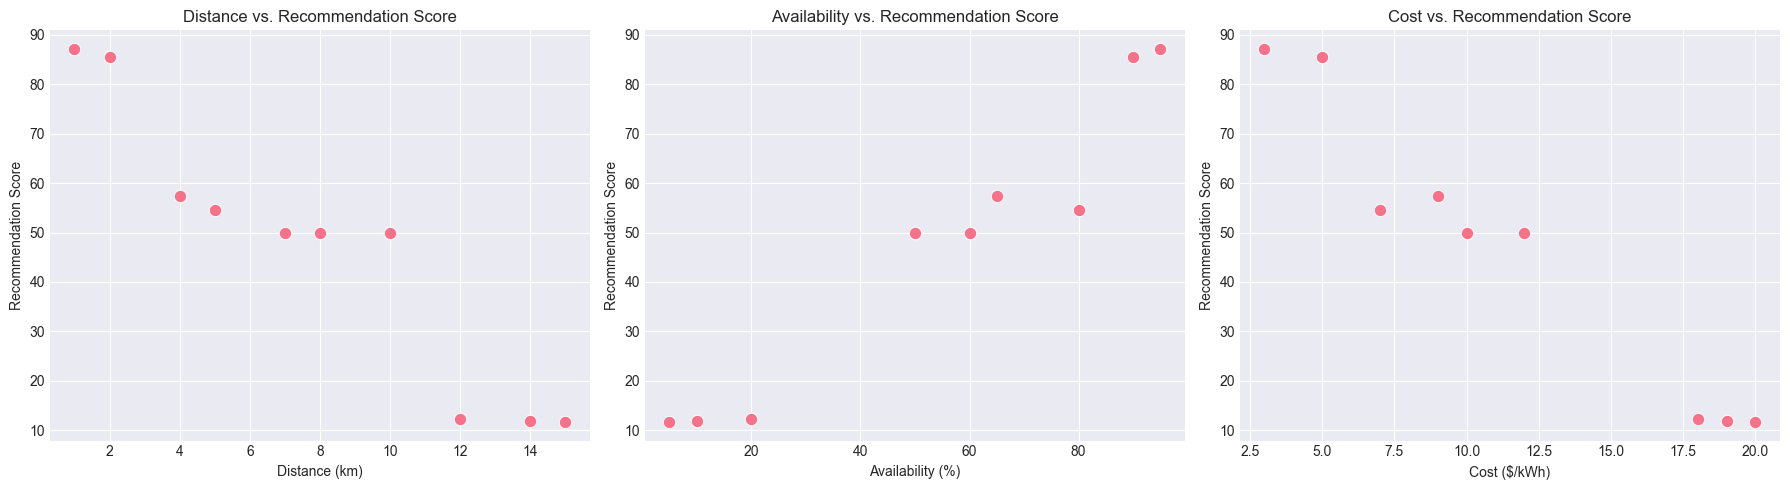

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
plots = [
    ("Distance (km)", "Distance vs. Recommendation Score"),
    ("Availability (%)", "Availability vs. Recommendation Score"),
    ("Cost ($/kWh)", "Cost vs. Recommendation Score"),
]
for axis, (x_column, title) in zip(axes, plots):
    sns.scatterplot(
        x=x_column,
        y="Recommendation Score",
        data=test_results_df,
        ax=axis,
        s=80,
    )
    axis.set_title(title)
    axis.grid(True)
plt.tight_layout()
plt.show()

## 3. Recommendation calculator

In [5]:
def display_recommendation(distance_val, availability_val, cost_val):
    """Print a readable recommendation for one charging station."""
    score = get_recommendation_score(distance_val, availability_val, cost_val)
    print("=" * 56)
    print("EV CHARGING STATION RECOMMENDATION")
    print("=" * 56)
    print(f"Distance: {distance_val:.1f} km")
    print(f"Availability: {availability_val:.1f}%")
    print(f"Charging cost: ${cost_val:.2f}/kWh")
    print("-" * 56)
    if np.isnan(score):
        print("Recommendation Score: unavailable")
        print("No fuzzy rule is activated for this combination.")
    else:
        print(f"Recommendation Score: {score:.2f}/100")
        if score >= 75:
            interpretation = "EXCELLENT - Highly recommended!"
        elif score >= 60:
            interpretation = "GOOD - Worth considering."
        elif score >= 45:
            interpretation = "FAIR - Acceptable option."
        else:
            interpretation = "POOR - Better alternatives are likely."
        print(interpretation)
    print("=" * 56)

display_recommendation(2, 90, 5)
display_recommendation(7, 60, 10)
display_recommendation(14, 10, 18)

EV CHARGING STATION RECOMMENDATION
Distance: 2.0 km
Availability: 90.0%
Charging cost: $5.00/kWh
--------------------------------------------------------
Recommendation Score: 85.53/100
EXCELLENT - Highly recommended!
EV CHARGING STATION RECOMMENDATION
Distance: 7.0 km
Availability: 60.0%
Charging cost: $10.00/kWh
--------------------------------------------------------
Recommendation Score: 50.00/100
FAIR - Acceptable option.
EV CHARGING STATION RECOMMENDATION
Distance: 14.0 km
Availability: 10.0%
Charging cost: $18.00/kWh
--------------------------------------------------------
Recommendation Score: 12.06/100
POOR - Better alternatives are likely.


## 4. Comprehensive system evaluation

The 20 × 20 × 20 grid contains 8,000 combinations. The `NaN` count is reported because the current rule base does not cover every possible combination; those cases are retained as missing rather than assigned an invented score.

In [6]:
n_points = 20
distances_test = np.linspace(0, 15, n_points)
availability_test = np.linspace(0, 100, n_points)
cost_test = np.linspace(0, 20, n_points)

D, A, C = np.meshgrid(distances_test, availability_test, cost_test)
test_data_comprehensive = pd.DataFrame({
    "distance": D.ravel(),
    "availability": A.ravel(),
    "cost": C.ravel(),
})

print(f"Generated {len(test_data_comprehensive):,} combinations.")
display(test_data_comprehensive.head())

Generated 8,000 combinations.


,distance,availability,cost
0,0.0,0.0,0.000000
1,0.0,0.0,1.052632
2,0.0,0.0,2.105263
3,0.0,0.0,3.157895
4,0.0,0.0,4.210526


In [7]:
print("Evaluating the fuzzy system on all combinations...")
test_data_comprehensive["recommendation_score"] = test_data_comprehensive.apply(
    lambda row: get_recommendation_score(
        row["distance"], row["availability"], row["cost"]
    ),
    axis=1,
)

scores = test_data_comprehensive["recommendation_score"]
print(f"Valid scores: {scores.notna().sum():,}")
print(f"Uncovered combinations: {scores.isna().sum():,}")
print(f"Minimum score: {scores.min():.2f}")
print(f"Maximum score: {scores.max():.2f}")
print(f"Mean score: {scores.mean():.2f}")
print(f"Standard deviation: {scores.std():.2f}")
display(test_data_comprehensive.head(10))

Evaluating the fuzzy system on all combinations...
Valid scores: 7,936
Uncovered combinations: 64
Minimum score: 11.67
Maximum score: 88.33
Mean score: 32.31
Standard deviation: 24.44


,distance,availability,cost,recommendation_score
0,0.0,0.0,0.000000,11.666667
1,0.0,0.0,1.052632,11.666667
2,0.0,0.0,2.105263,11.666667
3,0.0,0.0,3.157895,11.666667
4,0.0,0.0,4.210526,11.666667
5,0.0,0.0,5.263158,11.666667
6,0.0,0.0,6.315789,11.666667
7,0.0,0.0,7.368421,11.666667
8,0.0,0.0,8.421053,11.666667
9,0.0,0.0,9.473684,11.666667


## 5. Visualize the comprehensive response

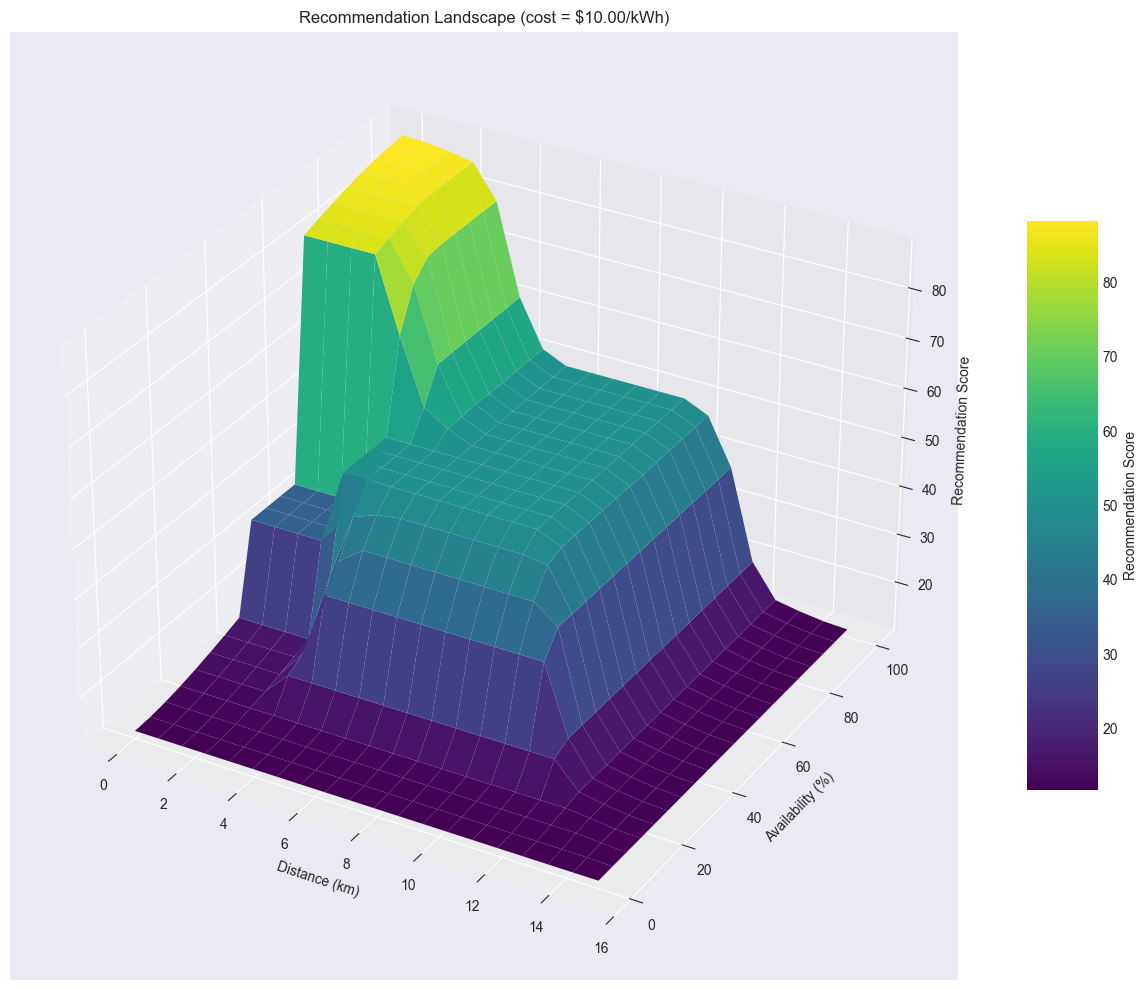

In [8]:
median_cost = float(np.median(cost_test))
X_plot, Y_plot = np.meshgrid(distances_test, availability_test)
Z_plot = np.full(X_plot.shape, np.nan)

for i in range(X_plot.shape[0]):
    for j in range(X_plot.shape[1]):
        Z_plot[i, j] = get_recommendation_score(
            X_plot[i, j], Y_plot[i, j], median_cost
        )

if np.isnan(Z_plot).all():
    print("No valid scores are available for the surface plot.")
else:
    plot_values = Z_plot.copy()
    plot_values[np.isnan(plot_values)] = np.nanmean(plot_values)
    fig = plt.figure(figsize=(14, 10))
    axis = fig.add_subplot(111, projection="3d")
    surface = axis.plot_surface(
        X_plot, Y_plot, plot_values, cmap="viridis", edgecolor="none"
    )
    axis.set_xlabel("Distance (km)")
    axis.set_ylabel("Availability (%)")
    axis.set_zlabel("Recommendation Score")
    axis.set_title(f"Recommendation Landscape (cost = ${median_cost:.2f}/kWh)")
    fig.colorbar(surface, shrink=0.6, aspect=8, label="Recommendation Score")
    plt.tight_layout()
    plt.show()

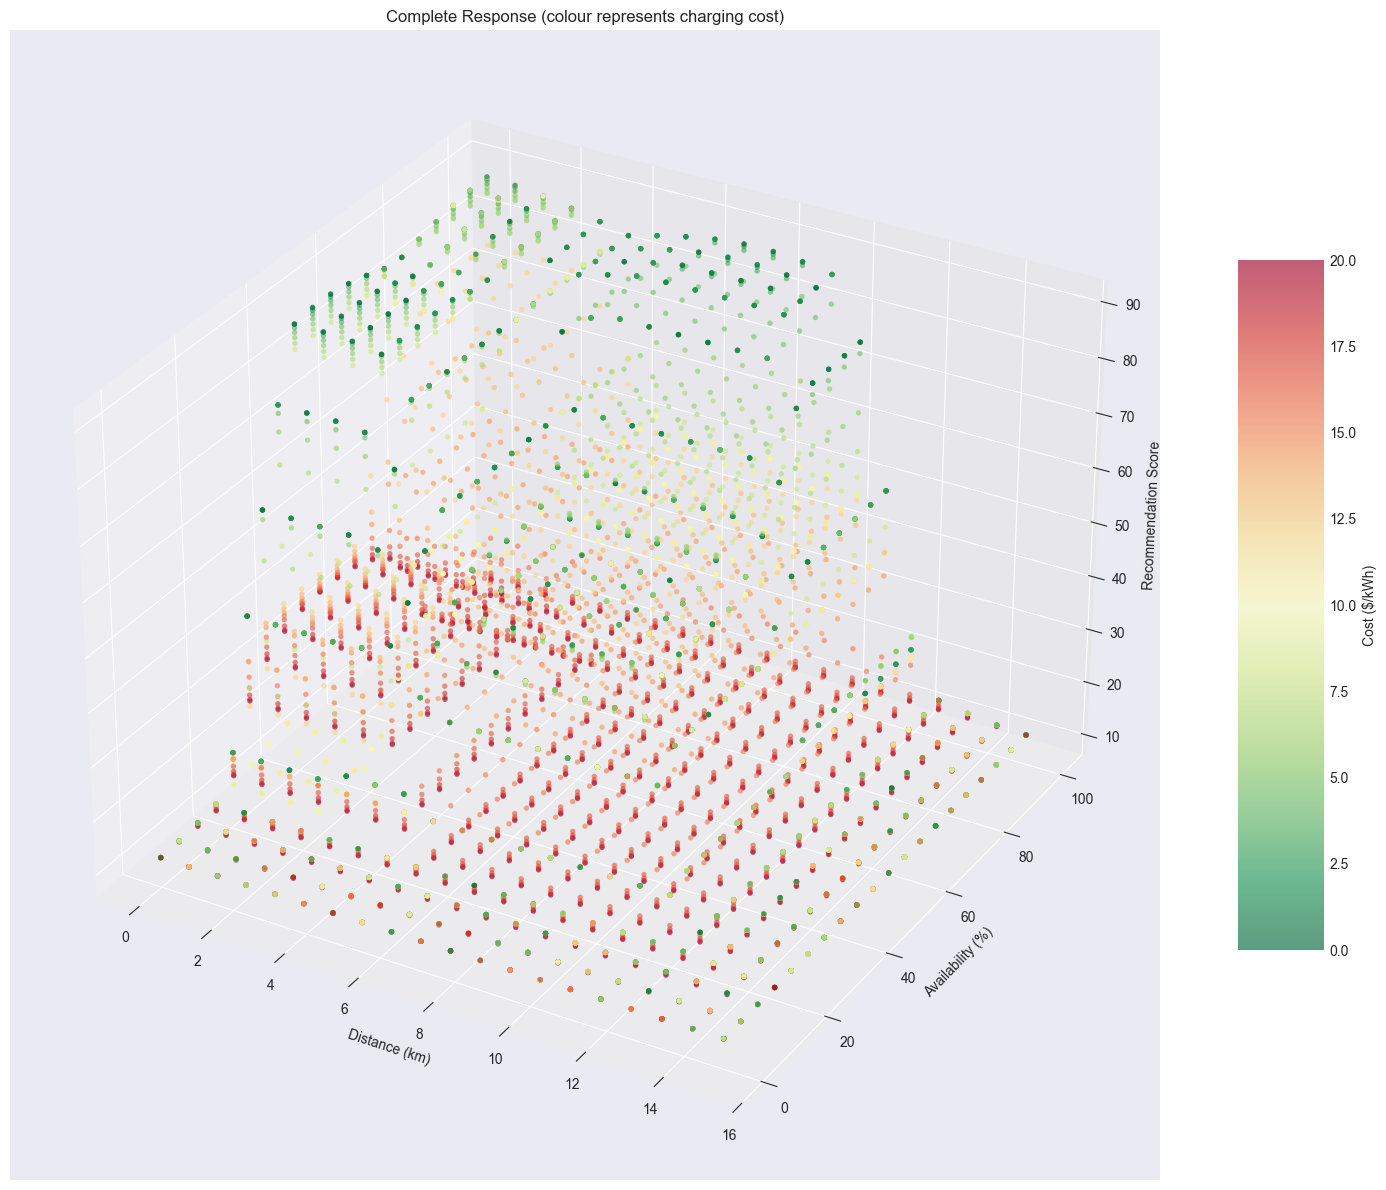

Plotted 7,936 valid combinations.


In [9]:
plot_data = test_data_comprehensive.dropna(subset=["recommendation_score"])
fig = plt.figure(figsize=(16, 12))
axis = fig.add_subplot(111, projection="3d")
scatter = axis.scatter(
    plot_data["distance"],
    plot_data["availability"],
    plot_data["recommendation_score"],
    c=plot_data["cost"],
    cmap="RdYlGn_r",
    s=15,
    alpha=0.6,
    edgecolors="none",
)
axis.set_xlabel("Distance (km)")
axis.set_ylabel("Availability (%)")
axis.set_zlabel("Recommendation Score")
axis.set_title("Complete Response (colour represents charging cost)")
fig.colorbar(scatter, shrink=0.6, aspect=8, label="Cost ($/kWh)")
plt.tight_layout()
plt.show()
print(f"Plotted {len(plot_data):,} valid combinations.")

## 6. Compare defuzzification methods

This preserves the old Milestone 3 comparison. The controller is reset to centroid after the comparison so later calculations use the project’s default method.

In [10]:
sample_input = {"distance": 4, "availability": 65, "cost": 9}
defuzzification_results = []
for method in VALID_DEFUZZIFICATION_METHODS:
    score = get_recommendation_score(
        sample_input["distance"],
        sample_input["availability"],
        sample_input["cost"],
        defuzzification_method=method,
    )
    defuzzification_results.append({
        "Method": method,
        "Recommendation Score": round(score, 2) if not np.isnan(score) else np.nan,
    })

defuzzification_df = pd.DataFrame(defuzzification_results)
display(defuzzification_df)
recommendation.defuzzify_method = "centroid"

,Method,Recommendation Score
0,centroid,57.32
1,bisector,56.16
2,mom,50.87
3,som,27.00
4,lom,73.33


## 7. Optional widget interface

The old Milestone 3 included sliders and a button. This section uses them when `ipywidgets` is available; otherwise the notebook remains fully usable through `display_recommendation()`.

In [ ]:
try:
    import ipywidgets as widgets

    distance_input = widgets.FloatSlider(
        value=4, min=0, max=15, step=0.1,
        description="Distance:", style={"description_width": "initial"},
    )
    availability_input = widgets.IntSlider(
        value=65, min=0, max=100, step=1,
        description="Availability:", style={"description_width": "initial"},
    )
    cost_input = widgets.FloatSlider(
        value=9, min=0, max=20, step=0.1,
        description="Cost:", style={"description_width": "initial"},
    )
    calculate_button = widgets.Button(
        description="Get Recommendation", button_style="primary"
    )
    widget_output = widgets.Output()

    def calculate_recommendation(_):
        with widget_output:
            clear_output()
            display_recommendation(
                distance_input.value,
                availability_input.value,
                cost_input.value,
            )

    calculate_button.on_click(calculate_recommendation)
    display(
        distance_input,
        availability_input,
        cost_input,
        calculate_button,
        widget_output,
    )
except ImportError:
    print("ipywidgets is not installed; use display_recommendation(...) instead.")

FloatSlider(value=4.0, description='Distance:', max=15.0, style=SliderStyle(description_width='initial'))

IntSlider(value=65, description='Availability:', style=SliderStyle(description_width='initial'))

FloatSlider(value=9.0, description='Cost:', max=20.0, style=SliderStyle(description_width='initial'))

Button(button_style='primary', description='Get Recommendation', style=ButtonStyle())

Output()

## 8. Final observations

The model gives higher scores to stations that are close, available, and inexpensive, while far, crowded, or expensive stations are penalized. The comprehensive evaluation also makes the current rule-base coverage visible. The next modelling improvement should be to add rules for the reported uncovered combinations and then compare the coverage and score distribution again.